In [ ]:
# Load MNIST Dataset

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

In [ ]:
# Train a simple MLP on MNIST dataset

In [ ]:
train = MNIST(".", train=True, download=True, transform=ToTensor())
test  = MNIST(".", train=False, download=True, transform=ToTensor())
train_dataset = DataLoader(train, batch_size=256, shuffle=True)
test_dataset = DataLoader(test,  batch_size=512)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28*28, 256), nn.ReLU(),
    nn.Linear(256, 128),   nn.ReLU(),
    nn.Linear(128, 10)  # no activation
)

opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossNetEntropyLoss() if hasattr(nn, "CrossNetEntropyLoss") else nn.CrossEntropyLoss()

for epoch in range(1, 5):
    model.train()
    for x,y in tr:
        opt.zero_grad()
        loss_fn(model(x), y).backward()
        opt.step()

    if epoch % 2 == 0:
        model.eval()
        correct = total = 0
        with torch.no_grad():
            for x,y in te:
                pred = model(x).argmax(1)
                correct += (pred == y).sum().item()
                total += y.numel()
        print(f"epoch {epoch} acc {correct/total:.4f}")


epoch 2 acc 0.9596
epoch 4 acc 0.9725


In [ ]:
# store the weights and biases

In [ ]:
# after training
wb = [{"W": m.weight.detach().cpu().clone(), "b": m.bias.detach().cpu().clone()}
      for m in model if isinstance(m, nn.Linear)]

torch.save(wb, "mlp_wb.pt")     # save
# wb = torch.load("mlp_wb.pt")  # load later


In [ ]:
# Create A_l for each layer

In [ ]:
# W: (n_l, n_{l-1}), b: (n_l,), l in {1..L}
def make_A(W, b, l, L):
    nl, nprev = W.shape
    k = L - l  # remaining layers after l
    top_left = torch.cat([W, b[:, None]], dim=1)  # [W_l  b_l] -> (nl, nprev+1)
    if k == 0:
        return top_left
    Ztr = torch.zeros(nl, k, dtype=W.dtype, device=W.device)          # 0_{nl x (L-l)}
    Zbl = torch.zeros(k, nprev + 1, dtype=W.dtype, device=W.device)   # 0_{(L-l) x (nprev+1)}
    Ibr = torch.eye(k, dtype=W.dtype, device=W.device)                # I_{L-l}
    return torch.cat([torch.cat([top_left, Ztr], 1),
                      torch.cat([Zbl, Ibr], 1)], 0)

# example: build A_l for each Linear layer you saved in wb
L = len(wb)
A = [make_A(wb[i]["W"], wb[i]["b"], i+1, L) for i in range(L)]


In [ ]:
# Now compute SVD for each A_l

In [ ]:
svds = [torch.linalg.svd(a, full_matrices=False) for a in A]

In [ ]:
# Create K_l - an approximation of A_l

In [ ]:

def make_Kl(A, n0, n_list):
    L = len(A)
    N = L + max([n0] + list(n_list))  # include n0

    Kl = []
    for Al in A:
        U, s, Vh = torch.linalg.svd(Al, full_matrices=True)
        p, q = Al.shape
        r = min(p, q)

        U_t = torch.block_diag(U, torch.eye(N - p, device=Al.device, dtype=Al.dtype))
        V_t = torch.block_diag(Vh.T, torch.eye(N - q, device=Al.device, dtype=Al.dtype))

        S_t = torch.eye(N, device=Al.device, dtype=Al.dtype)
        S_t[:r, :r] = torch.diag(s)

        Kl.append(U_t @ S_t @ V_t.T)
    return Kl, N

Kl, N = make_Kl(A, n0=784, n_list=[256,128,10])


In [ ]:
# Do the computations using K_l and ReLu

In [ ]:
# x: (n0,) or (n0,1); Kl: list of N×N; n_list: [n1,...,nL]
def forward_manual(x, Kl, n0, n_list):
    L, N = len(Kl), Kl[0].shape[0]
    a = x.view(n0, 1).to(device=Kl[0].device, dtype=Kl[0].dtype)

    for l in range(1, L + 1):
        ones = torch.ones(L - l + 1, 1, device=a.device, dtype=a.dtype)
        zeros = torch.zeros(N - a.shape[0] - (L - l + 1), 1, device=a.device, dtype=a.dtype)
        y_in = torch.cat([a, ones, zeros], dim=0)          # (N,1)

        y_out = Kl[l - 1] @ y_in                           # (N,1)
        z = y_out[:n_list[l - 1]]                          # (n_l,1)

        a = z if l == L else torch.relu(z)                 # no ReLU on last layer

    return a  # (10,1) for your network


In [ ]:
# Compare this K_l + ReLU vs MLP on 1 sample

In [ ]:
# grab 1 MNIST test sample
test = MNIST(".", train=False, download=True, transform=ToTensor())
img, y = test[0]                      # img: (1,28,28)
x = img.view(-1)                      # (784,)

model.eval()
with torch.no_grad():
    out_mlp = model(img.unsqueeze(0)).squeeze(0)          # (10,)
    out_man = forward_manual(x, Kl, n0=784, n_list=[256,128,10]).squeeze(1)  # (10,)

print("label:", y)
print("max|diff|:", (out_mlp - out_man).abs().max().item())
print("allclose:", torch.allclose(out_mlp, out_man, atol=1e-4, rtol=1e-4))
print("mlp logits:", out_mlp)
print("manual logits:", out_man)


label: 7
max|diff|: 1.6450881958007812e-05
allclose: True
mlp logits: tensor([ -1.7732,  -5.2756,   1.8979,   3.1684,  -7.2389,  -3.6842, -14.5471,
          9.4965,  -0.6912,   0.1590])
manual logits: tensor([ -1.7732,  -5.2756,   1.8979,   3.1684,  -7.2389,  -3.6842, -14.5471,
          9.4965,  -0.6912,   0.1590])


In [ ]:
# This isn’t really an approximation here—it’s a numerically stable reformulation with only tiny floating-point SVD/rounding differences.

In [ ]:
# Now save the ReLU output of each layer, later used to reconstruct the approximations

In [ ]:

# returns list [t_1,...,t_{L-1}], each (p_l,1) where p_l = n_l + (L-l)
def get_t_list(model, img):
    L = sum(isinstance(m, nn.Linear) for m in model)
    t = []
    a = img.view(1, -1)  # (1,n0)
    lin_i = 0

    for m in model:
        if isinstance(m, nn.Linear):
            lin_i += 1
            z = m(a)  # (1,n_l)
            if lin_i < L:  # no t_L
                a = torch.relu(z)
                ones = torch.ones(1, L - lin_i, device=a.device, dtype=a.dtype)
                t.append(torch.cat([a, ones], dim=1).T)  # (p_l,1)
            else:
                a = z
        elif isinstance(m, nn.Flatten):
            a = m(a)
    return t

# example:
t_list = get_t_list(model, img)


In [ ]:
# Compute R_l^SO and v_l

In [ ]:

def rot_u_to_w(u, w, eps=1e-12):
    # u,w: (p,1) unit vectors -> R in SO(p) with R@u = w
    p = u.size(0)
    I = torch.eye(p, device=u.device, dtype=u.dtype)
    c = (u.T @ w).clamp(-1.0, 1.0)  # (1,1)

    if (c > 1 - 1e-7).item():
        return I
    if (c < -1 + 1e-7).item():  # 180° case: pick any v ⟂ u
        e = torch.zeros_like(u); e[torch.argmin(u.abs())] = 1
        v = e - u * (u.T @ e)
        v = v / (v.norm() + eps)
        return I - 2 * (u @ u.T + v @ v.T)

    v = w - c * u
    v = v / (v.norm() + eps)
    s = torch.sqrt(1 - c * c)
    return I + (c - 1) * (u @ u.T + v @ v.T) + s * (v @ u.T - u @ v.T)

def compute_RSO_and_v(x, Kl, n0, n_list, t_list, eps=1e-12):
    L, N = len(Kl), Kl[0].shape[0]
    a = x.view(n0, 1).to(device=Kl[0].device, dtype=Kl[0].dtype)

    RSO, v = [], []
    for l in range(1, L + 1):
        ones  = torch.ones(L - l + 1, 1, device=a.device, dtype=a.dtype)
        zeros = torch.zeros(N - a.size(0) - (L - l + 1), 1, device=a.device, dtype=a.dtype)
        y_out = Kl[l - 1] @ torch.cat([a, ones, zeros], 0)  # (N,1)

        if l < L:
            p = n_list[l - 1] + (L - l)
            pre = y_out[:p]
            t = t_list[l - 1].to(device=pre.device, dtype=pre.dtype)

            np, nt = pre.norm(), t.norm()
            RSO.append(rot_u_to_w(pre/(np+eps), t/(nt+eps), eps=eps))
            v.append(nt/(np+eps))

        z = y_out[:n_list[l - 1]]
        a = z if l == L else torch.relu(z)

    return RSO, torch.stack(v)  # RSO: list of (p_l,p_l), v: (L-1,)

# example:
t_list = get_t_list(model, img)          # from earlier
RSO, v = compute_RSO_and_v(x, Kl, 784, [256,128,10], t_list)


In [ ]:
# Fully manual pass with no ReLU this time previously we used ReLU (both times uses K_l)

In [ ]:
# uses (RSO, v) to replace ReLU; no relu anywhere
def forward_no_relu(x, Kl, RSO, v, n0, n_list):
    L, N = len(Kl), Kl[0].shape[0]
    a = x.view(n0, 1).to(device=Kl[0].device, dtype=Kl[0].dtype)

    for l in range(1, L + 1):
        ones  = torch.ones(L - l + 1, 1, device=a.device, dtype=a.dtype)
        zeros = torch.zeros(N - a.size(0) - (L - l + 1), 1, device=a.device, dtype=a.dtype)
        y_out = Kl[l - 1] @ torch.cat([a, ones, zeros], 0)  # (N,1)

        if l < L:
            p = n_list[l - 1] + (L - l)
            pre = y_out[:p]                                  # (p_l,1)
            a = (v[l - 1] * (RSO[l - 1] @ pre))[:n_list[l - 1]]  # next a is (n_l,1)
        else:
            return y_out[:n_list[-1]]                         # (10,1)


In [ ]:
# Compare this no ReLU forward pass with the original MLP

In [ ]:

# sample
test = MNIST(".", train=False, download=True, transform=ToTensor())
img, y = test[0]
x = img.view(-1)

# original MLP output
model.eval()
with torch.no_grad():
    out_mlp = model(img.unsqueeze(0)).squeeze(0)  # (10,)

# no-relu forward output (needs RSO,v computed for this same sample)
out_nr = forward_no_relu(x, Kl, RSO, v, n0=784, n_list=[256,128,10]).squeeze(1)  # (10,)

print("label:", y)
print("max|diff|:", (out_mlp - out_nr).abs().max().item())
print("allclose:", torch.allclose(out_mlp, out_nr, atol=1e-4, rtol=1e-4))
print("mlp logits:", out_mlp)
print("no-relu logits:", out_nr)


label: 7
max|diff|: 9.5367431640625e-06
allclose: True
mlp logits: tensor([ -1.7732,  -5.2756,   1.8979,   3.1684,  -7.2389,  -3.6842, -14.5471,
          9.4965,  -0.6912,   0.1590])
no-relu logits: tensor([ -1.7732,  -5.2756,   1.8980,   3.1684,  -7.2389,  -3.6842, -14.5471,
          9.4966,  -0.6912,   0.1590], grad_fn=<SqueezeBackward1>)


In [ ]:
# The no-relu forward pass reproduces the original network output almost exactly for this sample, with very small numerical differences.
# This suggests the per-layer rotation and scaling construction is effectively substituting the relu behavior for that input, without changing the logits in practice.

In [ ]:
# Define Psi_x

In [ ]:
# x: (batch, n0) or (n0,)
def psi_x(x, L, N, n0):
    x = x.view(-1, n0)  # (B, n0)
    B = x.size(0)
    ones  = torch.ones(B, L, device=x.device, dtype=x.dtype)
    zeros = torch.zeros(B, N - n0 - L, device=x.device, dtype=x.dtype)
    return torch.cat([x, ones, zeros], dim=1).T  # (N, B); for single x -> (N,1)

In [ ]:
# Make Rhat matrix using R_l^SO and v_l

In [ ]:
# RSO[l]: (p_l,p_l), v[l]: scalar, N: int
def make_Rhat(RSO, v, N):
    Rhat = []
    for R, s in zip(RSO, v):
        p = R.size(0)
        Rhat.append(torch.block_diag((s * R), torch.eye(N - p, device=R.device, dtype=R.dtype)))
    # append identity as the last Rhat (e.g., R3)
    Rhat.append(torch.eye(N, device=Rhat[0].device, dtype=Rhat[0].dtype))
    return Rhat  # list of N×N

Rhat = make_Rhat(RSO, v, N)


In [ ]:
# Compute all the inverse K_l

In [ ]:
def invert_K_list(K_list):
    return [torch.linalg.inv(K) for K in K_list]  # each is N×N

# example:
K_inv_list = invert_K_list(Kl)


In [ ]:
# Construct K_theta as the ordered product of all layer maps so it represents the full linear part of the network acting on the embedded input

In [ ]:
def make_K_theta(K_list, dtype=torch.float64):
    dev = K_list[0].device
    N = K_list[0].shape[0]
    K_theta = torch.eye(N, dtype=dtype, device=dev)
    for K in K_list:
        K_theta = K.to(dtype=dtype) @ K_theta  # cast K to match dtype
    return K_theta

# example:
K_theta = make_K_theta(Kl, dtype=torch.float64)

In [ ]:
# Build a single square matrix phi (size N x N) by multiplying per-layer blocks in a specific order.

In [ ]:
def build_phi_no_RL(Rhat, Kl, K_inv_list, Pi=None):
    # Kl: [K1,...,KL], Rhat: [R1,...,RL]  (RL can be identity if you appended it)
    L = len(Kl)

    phi = Rhat[L-1]                 # start with R_L
    for l in range(L, 1, -1):       # l = L, L-1, ..., 2
        phi = phi @ Kl[l-1]         # ... @ K_l
        phi = phi @ Rhat[l-2]       # ... @ R_{l-1}

    # inverse tail: K2^{-1} ... KL^{-1}
    for l in range(2, L+1):
        phi = phi @ K_inv_list[l-1]

    return (Pi @ phi) if Pi is not None else phi

phi = build_phi_no_RL(Rhat, Kl, K_inv_list)


In [ ]:
# The inverse K terms inside phi cancel the matching K terms inside K_theta.
# So when we multiply phi by K_theta, all those K and inverse K pairs disappear.
# What remains is just the forward sequence where Rhat and K are interleaved and applied to the embedded input.

In [ ]:
# 1 forward pass using Phi . K_theta. Psi

In [ ]:
def forward_phi(x, phi, K_theta, L, n0=784, dtype=torch.float64):
    dev = phi.device
    N = K_theta.shape[0]

    psi_vec = psi_x(x.to(device=dev, dtype=dtype), L=L, N=N, n0=n0).to(dev, dtype)
    phi = phi.to(device=dev, dtype=dtype)
    K_theta = K_theta.to(device=dev, dtype=dtype)

    with torch.no_grad():
        y_tilde = phi @ (K_theta @ psi_vec)   # (N,1)
    return y_tilde[:10]


In [ ]:
# Compare output with original MLP

In [ ]:
# ----- load one MNIST sample -----
test = MNIST(root=".", train=False, download=True, transform=ToTensor())
img, y = test[0]                 # img: (1,28,28)
x = img.view(-1)                 # x: (784,)

# ----- MLP logits -----
model.eval()
with torch.no_grad():
    out_mlp = model(img.unsqueeze(0)).squeeze(0)   # (10,) float32 typically

# ----- phi-based logits -----
# forward_phi returns (10,1) in your implementation, so squeeze to (10,)
out_phi = forward_phi(x, phi, K_theta, L=3, n0=784).squeeze(1)  # (10,) float64 typically

# ----- compare safely (match dtypes) -----
out_phi_f = out_phi.to(dtype=out_mlp.dtype)  # cast to float32 to match out_mlp

print("label:", y)
print("mlp dtype:", out_mlp.dtype, "| phi dtype:", out_phi.dtype)
print("max|diff|:", (out_mlp - out_phi_f).abs().max().item())
print("allclose:", torch.allclose(out_mlp, out_phi_f, atol=1e-4, rtol=1e-4))
print("mlp logits:", out_mlp)
print("phi logits:", out_phi_f)


label: 7
mlp dtype: torch.float32 | phi dtype: torch.float64
max|diff|: 1.1324882507324219e-05
allclose: True
mlp logits: tensor([ -1.7732,  -5.2756,   1.8979,   3.1684,  -7.2389,  -3.6842, -14.5471,
          9.4965,  -0.6912,   0.1590])
phi logits: tensor([ -1.7732,  -5.2756,   1.8979,   3.1684,  -7.2389,  -3.6842, -14.5471,
          9.4965,  -0.6912,   0.1590])


In [ ]:
# Next we show that we can separate all the products and rotations from Rhat.

In [ ]:
# RSO[l]: (p_l,p_l), v[l]: scalar, N: int
def make_Rhat_separate(RSO, v, N):
    Rhat = []
    v_prod = None

    for R, s in zip(RSO, v):
        p = R.size(0)

        # rotation-only padded matrix
        Rhat.append(torch.block_diag(R, torch.eye(N - p, device=R.device, dtype=R.dtype)))

        # accumulate scalar product (as a tensor on the right device/dtype)
        s_t = torch.as_tensor(s, device=R.device, dtype=R.dtype)
        v_prod = s_t if v_prod is None else (v_prod * s_t)

    # append identity as the last Rhat (e.g., R3)
    Rhat.append(torch.eye(N, device=Rhat[0].device, dtype=Rhat[0].dtype))

    # if v was empty for some reason
    if v_prod is None:
        v_prod = torch.tensor(1.0, device=Rhat[0].device, dtype=Rhat[0].dtype)

    return Rhat, v_prod  # Rhat: list of N×N (no scalars), v_prod: scalar tensor

# usage
Rhat_sep, v_product = make_Rhat_separate(RSO, v, N)


def build_phi_no_RL_separate(Rhat_sep, Kl, K_inv_list, v_product, Pi=None):
    # Kl: [K1,...,KL], Rhat_sep: [R1,...,RL] (rotation-only; RL can be identity)
    L = len(Kl)

    phi = Rhat_sep[L-1]             # start with R_L (rotation-only)
    for l in range(L, 1, -1):       # l = L, L-1, ..., 2
        phi = phi @ Kl[l-1]         # ... @ K_l
        phi = phi @ Rhat_sep[l-2]   # ... @ R_{l-1}

    # inverse tail: K2^{-1} ... KL^{-1}
    for l in range(2, L+1):
        phi = phi @ K_inv_list[l-1]

    # apply all scalars once
    phi = phi * v_product

    return (Pi @ phi) if Pi is not None else phi

# usage:
# Rhat_sep, v_product = make_Rhat_separate(RSO, v, N)
phi = build_phi_no_RL_separate(Rhat_sep, Kl, K_inv_list, v_product)



def forward_phi2(x, phi, K_theta, L, n0=784, dtype=torch.float64):
    dev = phi.device
    N = K_theta.shape[0]

    psi_vec = psi_x(x.to(device=dev, dtype=dtype), L=L, N=N, n0=n0).to(dev, dtype)
    phi = phi.to(device=dev, dtype=dtype)
    K_theta = K_theta.to(device=dev, dtype=dtype)

    with torch.no_grad():
        y_tilde = phi @ (K_theta @ psi_vec)   # (N,1)
    return y_tilde[:10]

# ----- load one MNIST sample -----
test = MNIST(root=".", train=False, download=True, transform=ToTensor())
img, y = test[0]                 # img: (1,28,28)
x = img.view(-1)                 # x: (784,)

# ----- MLP logits -----
model.eval()
with torch.no_grad():
    out_mlp = model(img.unsqueeze(0)).squeeze(0)   # (10,) float32 typically

# ----- phi-based logits -----
# forward_phi returns (10,1) in your implementation, so squeeze to (10,)
out_phi = forward_phi2(x, phi, K_theta, L=3, n0=784).squeeze(1)  # (10,) float64 typically

# ----- compare safely (match dtypes) -----
out_phi_f = out_phi.to(dtype=out_mlp.dtype)  # cast to float32 to match out_mlp

print("label:", y)
print("mlp dtype:", out_mlp.dtype, "| phi dtype:", out_phi.dtype)
print("max|diff|:", (out_mlp - out_phi_f).abs().max().item())
print("allclose:", torch.allclose(out_mlp, out_phi_f, atol=1e-4, rtol=1e-4))
print("mlp logits:", out_mlp)
print("phi logits:", out_phi_f)



label: 7
mlp dtype: torch.float32 | phi dtype: torch.float64
max|diff|: 1.0251998901367188e-05
allclose: True
mlp logits: tensor([ -1.7732,  -5.2756,   1.8979,   3.1684,  -7.2389,  -3.6842, -14.5471,
          9.4965,  -0.6912,   0.1590])
phi logits: tensor([ -1.7732,  -5.2756,   1.8979,   3.1684,  -7.2389,  -3.6842, -14.5471,
          9.4965,  -0.6912,   0.1590])


In [ ]:
# Inference time comparison

In [ ]:
import time

def time_avg(fn, N=100, sync_cuda=True):
    # warmup
    for _ in range(10):
        fn()
    if sync_cuda and torch.cuda.is_available():
        torch.cuda.synchronize()

    t0 = time.perf_counter()
    for _ in range(N):
        fn()
    if sync_cuda and torch.cuda.is_available():
        torch.cuda.synchronize()
    t1 = time.perf_counter()

    return (t1 - t0) / N

N = 200  # <-- set N here (number of forward passes to average)

mlp_time = time_avg(lambda: model(img.unsqueeze(0)).squeeze(0), N=N)
phi_time = time_avg(lambda: forward_phi(x, phi, K_theta, L=3, n0=784).squeeze(1), N=N)

print(f"MLP avg forward over N={N}: {mlp_time*1e3:.3f} ms")
print(f"Phi avg forward over N={N}: {phi_time*1e3:.3f} ms")


MLP avg forward over N=200: 0.138 ms
Phi avg forward over N=200: 1.115 ms


In [ ]:
# KNN + cosine distance, with TTA and distance weighted voting for classification.

In [ ]:
# # --- Cosine kNN + zero-padded TTA + class shortlist (minimal) ---
# import torch
# import torch.nn.functional as F

# # assumes these already exist: K_list, psi_embed, train_loader, test_loader

# # knobs (override by setting globals before running)
# npc  = int(globals().get("max_train_per_class", 1000))
# k    = int(globals().get("k_neighbors", 31))
# tau  = float(globals().get("tau", 0.07))
# C    = int(globals().get("top_classes", 4))
# diag = bool(globals().get("use_diagonals", True))
# lim  = int(globals().get("num_test_limit", 2000))

# dev   = Kl[0].device
# dtype = torch.float64
# K_L   = Kl[-1].to(dev, dtype)
# n0 = 784
# N= 787
# L = 3

# @torch.no_grad()
# def embed(img):  # img: [1,28,28]
#     x = img.reshape(-1).to(dtype)
#     z = K_L @ psi_x(x.to(device=dev, dtype=dtype), L=L, N=N, n0=n0)
#     return z.reshape(-1)                    # <- make it [D]

# @torch.no_grad()
# def build_bank(npc):
#     cnt = torch.zeros(10, dtype=torch.long, device=dev)
#     V, y = [], []
#     for xb, yb in tr:
#         xb, yb = xb.to(dev), yb.to(dev)
#         for xi, yi in zip(xb, yb):
#             c = int(yi)
#             if cnt[c] >= npc:
#                 continue
#             V.append(embed(xi)); y.append(c)
#             cnt[c] += 1
#         if torch.all(cnt >= npc): break
#     V = torch.stack(V, 0).to(dtype).squeeze(-1)  # <- if it was [M,D,1], make [M,D]
#     y  = torch.tensor(y, device=dev, dtype=torch.long)     # [M]
#     Vn = V / (torch.linalg.norm(V, dim=1, keepdim=True) + 1e-12)
#     Pn = torch.stack([Vn[y==c].mean(0) for c in range(10)], 0)
#     Pn = Pn / (torch.linalg.norm(Pn, dim=1, keepdim=True) + 1e-12)
#     return Vn, y, Pn

# Vn, yb, Pn = build_bank(npc)
# print("Bank:", Vn.shape[0], "| per-class:", [int((yb==c).sum()) for c in range(10)])

# def shift_zeropad(x, dx, dy):
#     xpad = F.pad(x, (1,1,1,1))                 # [1,30,30]
#     y0 = max(0, min(2, 1 + dy))
#     x0 = max(0, min(2, 1 + dx))
#     return xpad[:, y0:y0+28, x0:x0+28]

# def views(x):
#     v = [x,
#          shift_zeropad(x, 1, 0), shift_zeropad(x,-1, 0),
#          shift_zeropad(x, 0, 1), shift_zeropad(x, 0,-1)]
#     if diag:
#         v += [shift_zeropad(x, 1, 1), shift_zeropad(x, 1,-1),
#               shift_zeropad(x,-1, 1), shift_zeropad(x,-1,-1)]
#     return v

# @torch.no_grad()
# def predict(x):
#     votes = torch.zeros(10, dtype=dtype, device=dev)
#     for img in views(x):
#         v  = embed(img)
#         vn = v / (torch.linalg.norm(v) + 1e-12)
#         keep = torch.topk(Pn @ vn, k=min(C,10)).indices
#         m    = torch.isin(yb, keep)
#         B, labs = Vn[m], yb[m]
#         d  = 1.0 - (B @ vn)
#         kk = min(k, B.shape[0])
#         topd, topi = torch.topk(d, k=kk, largest=False)
#         w  = torch.softmax(-topd / max(1e-6, tau), dim=0)
#         votes.index_add_(0, labs[topi], w.to(dtype))

#     winners = (votes == votes.max()).nonzero(as_tuple=True)[0]
#     if winners.numel() == 1:
#         return int(winners.item())

#     # tie-break: smallest mean cosine-distance to class bank (center view)
#     v0  = embed(x)
#     vn0 = v0 / (torch.linalg.norm(v0) + 1e-12)
#     d0  = 1.0 - (Vn @ vn0)
#     return min(winners.tolist(), key=lambda c: d0[yb==c].mean().item())

# @torch.no_grad()
# def eval_knn(limit=lim):
#     correct = total = 0
#     for xb, y in te:
#         xb, y = xb.to(dev), y.to(dev)
#         for xi, yi in zip(xb, y):
#             correct += int(predict(xi) == int(yi))
#             total += 1
#             if limit is not None and total >= limit:
#                 break
#         if limit is not None and total >= limit:
#             break
#     acc = 100.0 * correct / max(1, total)
#     print(f"Accuracy = {acc:.2f}% over {total} test samples.")
#     return acc, total

# acc, n = eval_knn()


Bank: 10000 | per-class: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
Accuracy = 91.80% over 2000 test samples.


In [ ]:
# - NOT testing phi(x) / the interspersed construction.
# - NOT "training" K_L (K_L is fixed).
# This is ONLY: feature extraction with v(x) = K_Last * psi(x), then cosine kNN classification.


In [ ]:
########################################## The end #########################################################################

In [ ]:
# NO SVD of A_l, so there will no K_l (havent checked the code fully yet)

In [ ]:
# # A: list of A_l as built by make_A
# # n0: input dimension
# # n_list: [n1, ..., nL]
# def forward_manual_A(x, A, n0, n_list):
#     L = len(A)
#     device = A[0].device
#     dtype = A[0].dtype

#     # start with a0 = x and append L ones for the bias "register"
#     a = x.view(n0, 1).to(device=device, dtype=dtype)   # (n0, 1)
#     ones_tail = torch.ones(L, 1, device=device, dtype=dtype)
#     s = torch.cat([a, ones_tail], dim=0)               # (n0 + L, 1)

#     for l in range(1, L + 1):
#         Al = A[l - 1]                                  # shape (n_l + L - l, n_{l-1} + 1 + L - l)
#         # shape sanity check (optional)
#         assert Al.shape[1] == s.shape[0], f"Shape mismatch at layer {l}: A_l has {Al.shape[1]} cols, state has {s.shape[0]} rows"

#         y = Al @ s                                     # (n_l + L - l, 1)
#         n_l = n_list[l - 1]

#         z = y[:n_l]                                    # pre-activation (n_l, 1)

#         if l < L:
#             a = torch.relu(z)                          # hidden layer activation
#             tail = y[n_l:]                             # (L - l, 1): bias "register" for remaining layers
#             s = torch.cat([a, tail], dim=0)            # state for next layer: (n_l + L - l, 1)
#         else:
#             # last layer: no ReLU
#             a = z                                      # (n_L, 1)

#     return a  # (n_L, 1)

# # W: (n_l, n_{l-1}), b: (n_l,), l in {1..L}
# def make_A(W, b, l, L):
#     nl, nprev = W.shape
#     k = L - l  # remaining layers after l
#     top_left = torch.cat([W, b[:, None]], dim=1)  # [W_l  b_l] -> (nl, nprev+1)
#     if k == 0:
#         return top_left
#     Ztr = torch.zeros(nl, k, dtype=W.dtype, device=W.device)          # 0_{nl x (L-l)}
#     Zbl = torch.zeros(k, nprev + 1, dtype=W.dtype, device=W.device)   # 0_{(L-l) x (nprev+1)}
#     Ibr = torch.eye(k, dtype=W.dtype, device=W.device)                # I_{L-l}
#     return torch.cat([torch.cat([top_left, Ztr], 1),
#                       torch.cat([Zbl, Ibr], 1)], 0)


# L = len(wb)  # wb: list of dicts {"W": W_l, "b": b_l}
# A = [make_A(wb[i]["W"], wb[i]["b"], i+1, L) for i in range(L)]

# # grab 1 MNIST test sample
# test = MNIST(".", train=False, download=True, transform=ToTensor())
# img, y = test[0]                      # img: (1,28,28)
# x = img.view(-1)                      # (784,)

# model.eval()
# with torch.no_grad():
#     out_mlp = model(img.unsqueeze(0)).squeeze(0)  # (10,)
#     out_manA = forward_manual_A(
#         x, A, n0=784, n_list=[256, 128, 10]
#     ).squeeze(1)                                   # (10,)

# print("label:", y)
# print("max|diff| (A):", (out_mlp - out_manA).abs().max().item())
# print("allclose (A):", torch.allclose(out_mlp, out_manA, atol=1e-4, rtol=1e-4))
# print("mlp logits:", out_mlp)
# print("manual logits (A):", out_manA)


label: 7
max|diff| (A): 9.5367431640625e-07
allclose (A): True
mlp logits: tensor([ -5.3942,  -6.3790,   1.6174,   5.0452, -13.7582,  -2.9135, -20.8055,
         13.7340,  -1.8595,  -1.0724])
manual logits (A): tensor([ -5.3942,  -6.3790,   1.6174,   5.0452, -13.7582,  -2.9135, -20.8055,
         13.7340,  -1.8595,  -1.0724])


In [ ]:
# import torch
# from torch import nn

# # returns list [t_1,...,t_{L-1}], each (p_l,1) where p_l = n_l + (L-l)
# def get_t_list(model, img):
#     L = sum(isinstance(m, nn.Linear) for m in model)
#     t = []
#     a = img.view(1, -1)  # (1,n0)
#     lin_i = 0

#     for m in model:
#         if isinstance(m, nn.Linear):
#             lin_i += 1
#             z = m(a)  # (1,n_l)
#             if lin_i < L:  # no t_L
#                 a = torch.relu(z)
#                 ones = torch.ones(1, L - lin_i, device=a.device, dtype=a.dtype)
#                 t.append(torch.cat([a, ones], dim=1).T)  # (p_l,1)
#             else:
#                 a = z
#         elif isinstance(m, nn.Flatten):
#             a = m(a)
#     return t


# def rot_u_to_w(u, w, eps=1e-12):
#     # u,w: (p,1) unit vectors -> R in SO(p) with R@u = w
#     p = u.size(0)
#     I = torch.eye(p, device=u.device, dtype=u.dtype)
#     c = (u.T @ w).clamp(-1.0, 1.0)  # (1,1)

#     if (c > 1 - 1e-7).item():
#         return I
#     if (c < -1 + 1e-7).item():  # 180° case: pick any v ⟂ u
#         e = torch.zeros_like(u); e[torch.argmin(u.abs())] = 1
#         v = e - u * (u.T @ e)
#         v = v / (v.norm() + eps)
#         return I - 2 * (u @ u.T + v @ v.T)

#     v = w - c * u
#     v = v / (v.norm() + eps)
#     s = torch.sqrt(1 - c * c)
#     return I + (c - 1) * (u @ u.T + v @ v.T) + s * (v @ u.T - u @ v.T)

# def compute_RSO_and_v_from_A(x, A, n0, n_list, t_list, eps=1e-12):
#     """
#     A: list of A_l matrices (each of shape (p_l, q_l))
#     n0: input dimension
#     n_list: [n1,...,nL]
#     t_list: [t_1,...,t_{L-1}], each (p_l,1)
#     """
#     L = len(A)
#     device = A[0].device
#     dtype = A[0].dtype

#     a = x.view(n0, 1).to(device=device, dtype=dtype)

#     RSO = []
#     v = []

#     for l in range(1, L + 1):
#         Al = A[l - 1]
#         n_l = n_list[l - 1]

#         # state going into layer l: [a_{l-1}; 1; ones_{L-l}]
#         tail_len = 1 + (L - l)  # = 1 for last layer
#         ones_tail = torch.ones(tail_len, 1, device=device, dtype=dtype)
#         s_in = torch.cat([a, ones_tail], dim=0)  # (q_l,1)

#         y = Al @ s_in  # (p_l,1) with p_l = n_l + (L-l)

#         if l < L:
#             pre = y                          # (p_l,1)
#             t = t_list[l - 1].to(device=device, dtype=dtype)  # (p_l,1)

#             np = pre.norm()
#             nt = t.norm()

#             RSO.append(rot_u_to_w(pre / (np + eps), t / (nt + eps), eps=eps))
#             v.append(nt / (np + eps))

#         # propagate with ReLU, as in the original network, to get a_{l}
#         z = y[:n_l]  # (n_l,1)
#         if l < L:
#             a = torch.relu(z)

#     return RSO, torch.stack(v)  # RSO: list of (p_l,p_l), v: (L-1,)

# def forward_no_relu_from_A(x, A, RSO, v, n0, n_list):
#     """
#     x: (n0,) or (n0,1)
#     A: list of A_l
#     RSO, v: from compute_RSO_and_v_from_A
#     n_list: [n1,...,nL]
#     """
#     L = len(A)
#     device = A[0].device
#     dtype = A[0].dtype

#     a = x.view(n0, 1).to(device=device, dtype=dtype)

#     for l in range(1, L + 1):
#         Al = A[l - 1]
#         n_l = n_list[l - 1]

#         # same state structure as in compute_RSO_and_v_from_A
#         tail_len = 1 + (L - l)
#         ones_tail = torch.ones(tail_len, 1, device=device, dtype=dtype)
#         s_in = torch.cat([a, ones_tail], dim=0)      # (q_l,1)

#         y = Al @ s_in                                # (p_l,1)

#         if l < L:
#             pre = y                                  # (p_l,1)
#             a = (v[l - 1] * (RSO[l - 1] @ pre))[:n_l]  # (n_l,1)
#         else:
#             # last layer: just linear
#             return y[:n_list[-1]]                    # (n_L,1)
# from torchvision.datasets import MNIST
# from torchvision.transforms import ToTensor

# # 1) Build A_l from saved weights/biases
# L = len(wb)
# A = [make_A(wb[i]["W"], wb[i]["b"], i + 1, L) for i in range(L)]

# # 2) Grab one MNIST sample
# test = MNIST(".", train=False, download=True, transform=ToTensor())
# img, y = test[0]
# x = img.view(-1)  # (784,)

# # 3) Original MLP output
# model.eval()
# with torch.no_grad():
#     out_mlp = model(img.unsqueeze(0)).squeeze(0)  # (10,)

# # 4) t_l from the original ReLU MLP
# t_list = get_t_list(model, img)  # len = L-1, each (p_l,1)

# # 5) Compute (RSO, v) using ONLY A_l
# n_list = [256, 128, 10]  # adjust to your architecture
# RSO_A, v_A = compute_RSO_and_v_from_A(x, A, n0=784, n_list=n_list, t_list=t_list)

# # 6) No-ReLU forward using A_l, RSO_A, v_A
# out_nr_A = forward_no_relu_from_A(x, A, RSO_A, v_A, n0=784, n_list=n_list).squeeze(1)  # (10,)

# print("label:", y)
# print("max|diff| (A no-ReLU):", (out_mlp - out_nr_A).abs().max().item())
# print("allclose (A no-ReLU):", torch.allclose(out_mlp, out_nr_A, atol=1e-4, rtol=1e-4))
# print("mlp logits:    ", out_mlp)
# print("no-relu logits:", out_nr_A)


label: 7
max|diff| (A no-ReLU): 3.814697265625e-06
allclose (A no-ReLU): True
mlp logits:     tensor([ -5.3942,  -6.3790,   1.6174,   5.0452, -13.7582,  -2.9135, -20.8055,
         13.7340,  -1.8595,  -1.0724])
no-relu logits: tensor([ -5.3942,  -6.3790,   1.6174,   5.0452, -13.7582,  -2.9135, -20.8055,
         13.7340,  -1.8595,  -1.0724], grad_fn=<SqueezeBackward1>)


In [ ]:
# import torch

# def build_M_and_d_from_A(A, RSO, v, n0, n_list, dtype=torch.float64):
#     """
#     A    : list of A_l (each (p_l, q_l) with p_l = n_l + (L-l), q_l = n_{l-1}+1+ (L-l))
#     RSO  : list of rotation matrices [R_1,...,R_{L-1}] from compute_RSO_and_v_from_A
#     v    : tensor of scalars (L-1,) from compute_RSO_and_v_from_A
#     n0   : input dim
#     n_list : [n1,...,nL]
#     """
#     L = len(A)
#     dev = A[0].device

#     M_list, d_list = [], []

#     for l in range(1, L + 1):
#         Al = A[l - 1].to(device=dev, dtype=dtype)

#         n_prev = n0 if l == 1 else n_list[l - 2]
#         n_curr = n_list[l - 1]

#         p_l = n_curr + (L - l)
#         q_l = n_prev + 1 + (L - l)

#         assert Al.shape == (p_l, q_l), f"A[{l-1}] shape {Al.shape} != {(p_l, q_l)}"

#         # P_l: picks a_{l-1} into the first n_prev entries of s_in = [a_{l-1}; 1; ...; 1]
#         P_l = torch.zeros(q_l, n_prev, device=dev, dtype=dtype)
#         P_l[:n_prev, :n_prev] = torch.eye(n_prev, device=dev, dtype=dtype)

#         # c_l: constant part (zeros then ones)
#         c_l = torch.zeros(q_l, 1, device=dev, dtype=dtype)
#         c_l[n_prev:, 0] = 1.0

#         # A_l [a_{l-1}; ones] = T_l a_{l-1} + b'_l
#         T_l = Al @ P_l          # (p_l, n_prev)
#         b_l_prime = Al @ c_l    # (p_l, 1)

#         # Q_l: take first n_l coordinates (pre-activation part)
#         Q_l = torch.zeros(n_curr, p_l, device=dev, dtype=dtype)
#         Q_l[:, :n_curr] = torch.eye(n_curr, device=dev, dtype=dtype)

#         if l < L:
#             R_l = RSO[l - 1].to(device=dev, dtype=dtype)    # (p_l, p_l)
#             s_l = v[l - 1].to(device=dev, dtype=dtype)      # scalar
#             R_scaled = s_l * R_l

#             M_l = Q_l @ (R_scaled @ T_l)        # (n_l, n_{l-1})
#             d_l = Q_l @ (R_scaled @ b_l_prime)  # (n_l, 1)
#         else:
#             # last layer: no rotation, just take first n_L entries
#             M_l = Q_l @ T_l                      # (n_L, n_{L-1})
#             d_l = Q_l @ b_l_prime                # (n_L, 1)

#         M_list.append(M_l)
#         d_list.append(d_l)

#     return M_list, d_list

# def collapse_affine_chain(M_list, d_list):
#     """
#     Given a_l = M_l a_{l-1} + d_l, collapse into
#     a_L = W_eff a_0 + b_eff.
#     """
#     L = len(M_list)
#     assert len(d_list) == L

#     W_eff = M_list[0]
#     b_eff = d_list[0]

#     for l in range(1, L):
#         W_eff = M_list[l] @ W_eff
#         b_eff = M_list[l] @ b_eff + d_list[l]

#     return W_eff, b_eff  # shapes: (n_L, n0), (n_L, 1)
# def build_phi_no_RL_from_A(A, RSO, v, n0, n_list, dtype=torch.float64):
#     """
#     Returns:
#         phi_A : (N, N) global linear map using only A_l + (RSO, v)
#         N     : ambient dimension used by psi_x
#     """
#     L = len(A)
#     dev = A[0].device

#     # same N you used for K_l: L + max(n0, n1,...,nL)
#     N = L + max([n0] + list(n_list))

#     # 1) per-layer linear pieces
#     M_list, d_list = build_M_and_d_from_A(A, RSO, v, n0, n_list, dtype=dtype)

#     # 2) collapse into single W*, b*
#     W_eff, b_eff = collapse_affine_chain(M_list, d_list)  # (n_L, n0), (n_L,1)
#     n_out = n_list[-1]

#     phi = torch.zeros(N, N, device=dev, dtype=dtype)

#     # contribution from x part (first n0 coords in psi_x)
#     phi[:n_out, :n0] = W_eff  # (n_out, n0)

#     # contribution from the L "ones" coords (next L coords in psi_x)
#     if L > 0:
#         b_col = b_eff / L                      # (n_out, 1)
#         phi[:n_out, n0:n0 + L] = b_col.repeat(1, L)  # (n_out, L)

#     # remaining rows/cols can stay zero – they don't affect logits
#     return phi, N
# def forward_phi_A(x, phi, L, N, n0, n_out, dtype=torch.float64):
#     dev = phi.device

#     psi_vec = psi_x(x.to(device=dev, dtype=dtype), L=L, N=N, n0=n0)  # (N,1)
#     phi = phi.to(device=dev, dtype=dtype)

#     with torch.no_grad():
#         y_tilde = phi @ psi_vec   # (N,1)

#     return y_tilde[:n_out]        # (n_out,1)
# # ----- architecture info -----
# n0 = 784
# n_list = [256, 128, 10]
# L = len(n_list)

# # A_l list already built from weights/biases:
# # A = [make_A(wb[i]["W"], wb[i]["b"], i+1, L) for i in range(L)]

# # ----- sample -----
# from torchvision.datasets import MNIST
# from torchvision.transforms import ToTensor

# test = MNIST(".", train=False, download=True, transform=ToTensor())
# img, y = test[0]
# x = img.view(-1)  # (784,)

# # ----- original MLP output -----
# model.eval()
# with torch.no_grad():
#     out_mlp = model(img.unsqueeze(0)).squeeze(0)  # (10,)

# # ----- get t_l (same as you already do) -----
# t_list = get_t_list(model, img)

# # ----- rotations & scales from A_l only -----
# RSO_A, v_A = compute_RSO_and_v_from_A(x, A, n0=n0, n_list=n_list, t_list=t_list)

# # ----- build phi using only A_l, RSO_A, v_A -----
# phi_A, N = build_phi_no_RL_from_A(A, RSO_A, v_A, n0=n0, n_list=n_list, dtype=torch.float64)

# # ----- phi-based logits -----
# out_phi_A = forward_phi_A(x, phi_A, L=L, N=N, n0=n0, n_out=n_list[-1]).squeeze(1)  # (10,)

# # match dtypes to compare
# out_phi_A_f = out_phi_A.to(dtype=out_mlp.dtype)

# print("label:", y)
# print("mlp dtype:", out_mlp.dtype, "| phi_A dtype:", out_phi_A.dtype)
# print("max|diff|:", (out_mlp - out_phi_A_f).abs().max().item())
# print("allclose:", torch.allclose(out_mlp, out_phi_A_f, atol=1e-4, rtol=1e-4))
# print("mlp logits:", out_mlp)
# print("phi_A logits:", out_phi_A_f)


label: 7
mlp dtype: torch.float32 | phi_A dtype: torch.float64
max|diff|: 3.814697265625e-06
allclose: True
mlp logits: tensor([ -5.3942,  -6.3790,   1.6174,   5.0452, -13.7582,  -2.9135, -20.8055,
         13.7340,  -1.8595,  -1.0724])
phi_A logits: tensor([ -5.3942,  -6.3790,   1.6174,   5.0452, -13.7582,  -2.9135, -20.8055,
         13.7340,  -1.8595,  -1.0724])


In [ ]:
# Phi(class) instead of Phi(x)

accuracy matrix (rows=true class, cols=phi_class index):
 tensor([[0.9684, 0.3296, 0.7347, 0.6316, 0.6439, 0.6837, 0.7643, 0.6878, 0.6408,
         0.6082],
        [0.0000, 0.4758, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0070,
         0.0000],
        [0.4409, 0.4118, 0.6967, 0.3924, 0.3207, 0.2413, 0.3576, 0.3459, 0.3750,
         0.2636],
        [0.8495, 0.8000, 0.8554, 0.8851, 0.7376, 0.8743, 0.7960, 0.8109, 0.8178,
         0.7871],
        [0.7739, 0.6558, 0.7597, 0.7271, 0.8401, 0.7189, 0.8136, 0.8086, 0.8381,
         0.8259],
        [0.1110, 0.0404, 0.0348, 0.1502, 0.0785, 0.3531, 0.0762, 0.0594, 0.1558,
         0.1043],
        [0.8069, 0.7119, 0.6743, 0.6681, 0.7171, 0.7693, 0.8664, 0.6138, 0.7557,
         0.6764],
        [0.2257, 0.2257, 0.2656, 0.3123, 0.2967, 0.2101, 0.0914, 0.4874, 0.3696,
         0.3930],
        [0.9641, 0.9867, 0.9743, 0.9661, 0.9805, 0.9774, 0.9805, 0.9795, 0.9723,
         0.9764],
        [0.7701, 0.7839, 0.8067, 0.7909, 0.8266, 0.

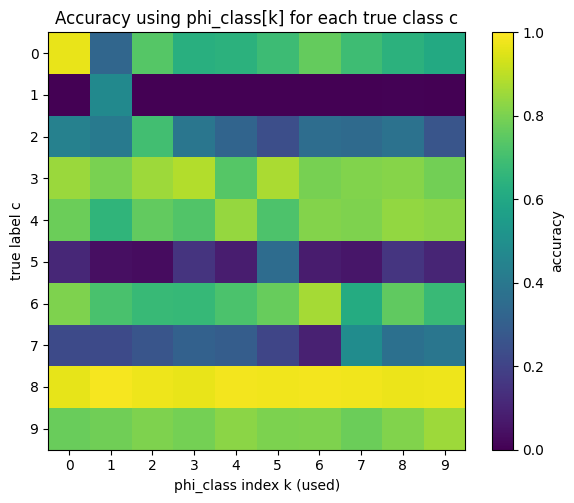

In [ ]:

import matplotlib.pyplot as plt

# ----- assumptions / settings -----
# model, Kl, N, K_theta, get_t_list, compute_RSO_and_v,
# make_Rhat, invert_K_list, build_phi_no_RL, psi_x, forward_phi
# are already defined as in your previous code.

n0 = 784
n_list = [256, 128, 10]
L = len(Kl)
num_classes = 10
num_per_class = 1000  # use more samples per class

device = Kl[0].device
dtype  = Kl[0].dtype

train = MNIST(root=".", train=True,  download=True, transform=ToTensor())
test  = MNIST(root=".", train=False, download=True, transform=ToTensor())

K_inv_list = invert_K_list(Kl)

# ----- 1) build phi_class[c] from TRAIN data only -----
phi_sum = [torch.zeros(N, N, device=device, dtype=dtype) for _ in range(num_classes)]
counts  = [0] * num_classes

model.eval()
with torch.no_grad():
    for img, label in train:
        c = int(label)
        if counts[c] >= num_per_class:
            continue

        img = img.to(device)
        x   = img.view(-1)

        t_list = get_t_list(model, img)  # uses the same img (already on device)
        RSO, v = compute_RSO_and_v(x, Kl, n0=n0, n_list=n_list, t_list=t_list)
        Rhat   = make_Rhat(RSO, v, N)
        phi_x  = build_phi_no_RL(Rhat, Kl, K_inv_list)  # (N, N)

        phi_sum[c] += phi_x
        counts[c]  += 1

        if all(cnt >= num_per_class for cnt in counts):
            break

phi_class = [phi_sum[c] / counts[c] for c in range(num_classes)]

# ----- 2) build 10x10 accuracy matrix on TEST data -----
acc_counts = torch.zeros(num_classes, num_classes, dtype=torch.int64)
totals     = torch.zeros(num_classes, dtype=torch.int64)

with torch.no_grad():
    for img, label in test:
        img = img.to(device)
        x   = img.view(-1)
        c   = int(label)

        totals[c] += 1

        for k in range(num_classes):
            logits = forward_phi(
                x,
                phi_class[k],
                K_theta,
                L=L,
                n0=n0,
                dtype=K_theta.dtype  # ensure consistent precision
            ).squeeze(1)  # (10,)

            pred = logits.argmax().item()
            if pred == c:
                acc_counts[c, k] += 1

acc_matrix = acc_counts.float() / totals.view(-1, 1)  # (10,10)

print("accuracy matrix (rows=true class, cols=phi_class index):\n", acc_matrix)

# ----- 3) plot the matrix -----
plt.figure(figsize=(6, 5))
im = plt.imshow(acc_matrix.cpu().numpy(), vmin=0.0, vmax=1.0)
plt.colorbar(im, label="accuracy")
plt.xlabel("phi_class index k (used)")
plt.ylabel("true label c")
plt.xticks(range(num_classes))
plt.yticks(range(num_classes))
plt.title("Accuracy using phi_class[k] for each true class c")
plt.tight_layout()
plt.show()


In [ ]:




# ------------------------------
# 1) Build dataset: (x -> phi_x)
# ------------------------------
@torch.no_grad()
def compute_phi_from_img(img: torch.Tensor) -> torch.Tensor:
    """
    img: (1,28,28) on device
    returns phi_x: (N, N) on device
    """
    x = img.view(-1)  # (784,)
    t_list = get_t_list(model, img)  # assumes img is on device
    RSO, v = compute_RSO_and_v(x, Kl, n0=n0, n_list=n_list, t_list=t_list)
    Rhat   = make_Rhat(RSO, v, N)
    phi_x  = build_phi_no_RL(Rhat, Kl, K_inv_list)  # (N, N)
    return phi_x

def build_phi_dataset_from_mnist(mnist_ds, num_per_class=1000):
    """
    Precomputes a balanced dataset across classes.
    Stores X and Y on CPU for memory efficiency.
      X: (M, 784)
      Y: (M, N*N)  (flattened phi_x)
    """
    model.eval()

    counts = [0] * num_classes
    X_list, Y_list = [], []

    for img, label in mnist_ds:
        c = int(label)
        if counts[c] >= num_per_class:
            continue

        img = img.to(device)
        phi_x = compute_phi_from_img(img)  # (N,N) on device

        x_cpu   = img.view(-1).detach().float().cpu()              # (784,)
        phi_cpu = phi_x.detach().to(torch.float32).reshape(-1).cpu()  # (N*N,)

        X_list.append(x_cpu)
        Y_list.append(phi_cpu)
        counts[c] += 1

        if all(cnt >= num_per_class for cnt in counts):
            break

    X = torch.stack(X_list, dim=0)  # (M, 784)
    Y = torch.stack(Y_list, dim=0)  # (M, N*N)
    return X, Y, counts

X, Y, counts = build_phi_dataset_from_mnist(train, num_per_class=num_per_class)
print("Counts per class:", counts)
print("X shape:", X.shape, "Y shape:", Y.shape)

class PhiRegressionDataset(Dataset):
    def __init__(self, X_cpu: torch.Tensor, Y_cpu: torch.Tensor):
        self.X = X_cpu
        self.Y = Y_cpu

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]

full_ds = PhiRegressionDataset(X, Y)

# Train/val split
val_frac = 0.15
n_val = int(len(full_ds) * val_frac)
n_train = len(full_ds) - n_val
train_ds, val_ds = random_split(full_ds, [n_train, n_val], generator=torch.Generator().manual_seed(0))

batch_size = 512
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)




In [ ]:
# ------------------------------
# 2) 1-layer "MLP": Linear only
# ------------------------------
class OneLayerMLP(nn.Module):
    def __init__(self, in_dim=784, out_dim=None):
        super().__init__()
        assert out_dim is not None
        self.fc = nn.Linear(in_dim, out_dim)

    def forward(self, x):
        # x: (B, 784)
        return self.fc(x)

out_dim = N * N
mlp = OneLayerMLP(in_dim=784, out_dim=out_dim).to(device)

# ------------------------------
# 3) Train (regression to phi_x)
# ------------------------------
def run_epoch(model, loader, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)

    total_loss = 0.0
    total_n = 0

    for xb_cpu, yb_cpu in loader:
        xb = xb_cpu.to(device, non_blocking=True)
        yb = yb_cpu.to(device, non_blocking=True)

        pred = model(xb)  # (B, N*N)
        loss = F.mse_loss(pred, yb)

        if is_train:
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

        bs = xb.size(0)
        total_loss += loss.item() * bs
        total_n += bs

    return total_loss / max(1, total_n)

lr = 1e-3
weight_decay = 0.0
optimizer = torch.optim.Adam(mlp.parameters(), lr=lr, weight_decay=weight_decay)


epochs = 3
for epoch in range(1, epochs + 1):
    train_loss = run_epoch(mlp, train_loader, optimizer=optimizer)
    val_loss   = run_epoch(mlp, val_loader, optimizer=None)
    print(f"Epoch {epoch:02d} | train MSE: {train_loss:.6e} | val MSE: {val_loss:.6e}")

# ------------------------------
# 4) Using the trained MLP
# ------------------------------
@torch.no_grad()
@torch.no_grad()
def predict_phi_from_x_batch(x_flat: torch.Tensor) -> torch.Tensor:
    # x_flat: (B,784) or (784,)
    if x_flat.dim() == 1:
        x_flat = x_flat.unsqueeze(0)
    x_flat = x_flat.to(device)
    y = mlp(x_flat)                 # (B, N*N)
    return y.view(-1, N, N)         # (B, N, N)


# Example:
img0, _ = train[0]
phi_pred = predict_phi_from_x_batch(img0.view(-1))
print("phi_pred shape:", phi_pred.shape)  # (N, N)

In [ ]:
import torch
from torch.utils.data import DataLoader

# Assumes: mlp, forward_phi/psi_x exist (we'll add batched forward below),
#          K_theta, N, L, n0, device, test

mlp.eval()

# ---- pre-cast once (avoid doing this every call) ----
K_theta_b = K_theta.to(device=device, dtype=K_theta.dtype)

@torch.no_grad()
def phi_from_mlp_batch(x_flat: torch.Tensor) -> torch.Tensor:
    """
    x_flat: (B, 784) or (784,)
    returns: (B, N, N) (or (1,N,N) if single) on device, dtype=K_theta.dtype
    """
    if x_flat.dim() == 1:
        x_flat = x_flat.unsqueeze(0)  # (1,784)
    x_flat = x_flat.to(device)

    phi_flat = mlp(x_flat)  # (B, N*N)
    phi = phi_flat.view(-1, N, N).to(dtype=K_theta_b.dtype)  # (B,N,N)
    return phi

@torch.no_grad()
def forward_phi_batch(x, phi, K_theta, L, n0=784, dtype=torch.float64):
    """
    x  : (B, n0) or (n0,)
    phi: (B, N, N)  OR (N, N) (shared)
    returns logits: (B, 10)
    """
    dev = K_theta.device
    if x.dim() == 1:
        x = x.unsqueeze(0)  # (1,n0)
    x = x.to(device=dev, dtype=dtype)

    # psi_x returns (N, B)
    psi = psi_x(x, L=L, N=K_theta.shape[0], n0=n0).to(dev, dtype)     # (N,B)
    Kpsi = (K_theta.to(dtype=dtype) @ psi)                              # (N,B)

    # Apply phi
    if phi.dim() == 2:
        # shared phi: (N,N) @ (N,B) -> (N,B)
        y = (phi.to(dev, dtype) @ Kpsi).T                               # (B,N)
    else:
        # per-sample phi: bmm( (B,N,N), (B,N,1) ) -> (B,N,1) -> (B,N)
        phi = phi.to(dev, dtype)                                        # (B,N,N)
        Kpsi_vec = Kpsi.T.unsqueeze(-1)                                 # (B,N,1)
        y = torch.bmm(phi, Kpsi_vec).squeeze(-1)                        # (B,N)

    return y[:, :10]  # (B,10)

# ----- Batched test accuracy -----
batch_size = 1024
loader = DataLoader(test, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=(device.type=="cuda"))

correct = 0
total = 0

with torch.no_grad():
    for imgs, labels in loader:
        imgs = imgs.to(device)
        x = imgs.view(imgs.size(0), -1)              # (B,784)
        labels = labels.to(device)

        phi_hat = phi_from_mlp_batch(x)              # (B,N,N)
        logits  = forward_phi_batch(x, phi_hat, K_theta_b, L=L, n0=n0, dtype=K_theta_b.dtype)  # (B,10)

        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.numel()

print(f"Test accuracy (batched phi-MLP + forward_phi): {correct/total:.4f}")


In [ ]:
import time
import torch
from torch.utils.data import DataLoader, Subset

# assumes: test (MNIST), device, model (pretrained), mlp (phi-MLP),
#          forward_phi_batch (batched version), K_theta, N, L, n0

mlp.eval()
model.eval()

# ---- settings ----
B = 200                      # SAME batch size for both paths
num_samples = 200
idx = list(range(num_samples))
loader = DataLoader(Subset(test, idx), batch_size=B, shuffle=False)

def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

@torch.no_grad()
def phi_from_mlp_batch(x_flat):          # x_flat: (B,784)
    phi_flat = mlp(x_flat)              # (B, N*N)
    return phi_flat.view(-1, N, N).to(K_theta.dtype)  # (B,N,N)

# -------- warmup --------
with torch.no_grad():
    for i, (imgs, _) in enumerate(loader):
        if i >= 2: break
        imgs = imgs.to(device)
        x = imgs.view(imgs.size(0), -1)               # (B,784)
        phi = phi_from_mlp_batch(x)
        _ = forward_phi_batch(x, phi, K_theta, L=L, n0=n0, dtype=K_theta.dtype)  # (B,10)
        _ = model(imgs)  # imgs already (B,1,28,28)
sync()

# -------- time: phi-MLP + forward_phi_batch --------
t0 = time.perf_counter()
with torch.no_grad():
    for imgs, _ in loader:
        imgs = imgs.to(device)
        x = imgs.view(imgs.size(0), -1)
        phi = phi_from_mlp_batch(x)
        _ = forward_phi_batch(x, phi, K_theta, L=L, n0=n0, dtype=K_theta.dtype)
sync()
t1 = time.perf_counter()

# -------- time: pretrained model forward --------
t2 = time.perf_counter()
with torch.no_grad():
    for imgs, _ in loader:
        imgs = imgs.to(device)
        _ = model(imgs)
sync()
t3 = time.perf_counter()

phi_path_total = t1 - t0
orig_total = t3 - t2
n = num_samples

print(f"batch_size={B}, n={n}")
print(f"phi-MLP + forward_phi: total {phi_path_total:.6f}s | per-sample {phi_path_total/n*1e3:.3f} ms")
print(f"pretrained model fwd : total {orig_total:.6f}s | per-sample {orig_total/n*1e3:.3f} ms")
